1. Direct Line Equation Scan Conversion

Enter x1: 0
Enter y1: 0
Enter x2: 7
Enter y2: 10

 ---Direct Line Equation Method--- 
Starting point:  0 0
Ending point:  7 10
Slope: 1.4285714285714286
Y-intercept: 0.0
Case: Steep Line.

x=0, y=0, pixels -> (0, 0)
x=1, y=1, pixels -> (1, 1)
x=1, y=2, pixels -> (1, 2)
x=2, y=3, pixels -> (2, 3)
x=3, y=4, pixels -> (3, 4)
x=4, y=5, pixels -> (4, 5)
x=4, y=6, pixels -> (4, 6)
x=5, y=7, pixels -> (5, 7)
x=6, y=8, pixels -> (6, 8)
x=6, y=9, pixels -> (6, 9)
x=7, y=10, pixels -> (7, 10)
[(0, 0), (1, 1), (1, 2), (2, 3), (3, 4), (4, 5), (4, 6), (5, 7), (6, 8), (6, 9), (7, 10)]


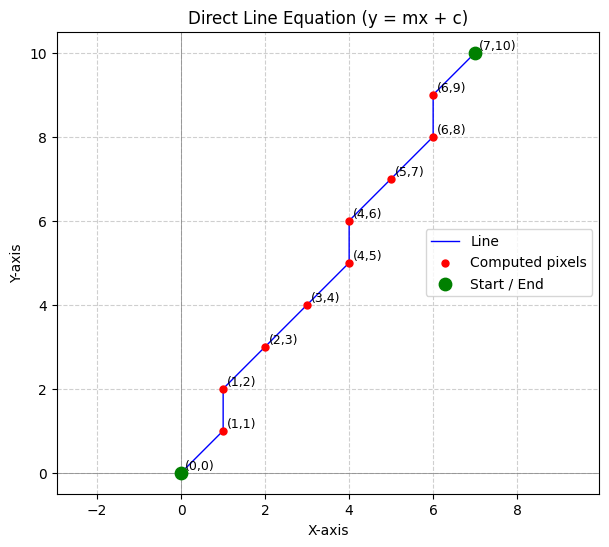

In [3]:
import matplotlib.pyplot as plt
def direct_line(x1,y1,x2,y2):
  pixels = []
  print("\n ---Direct Line Equation Method--- ")
  print("Starting point: ",x1,y1)
  print("Ending point: ",x2,y2)
  dx = x2 - x1
  dy = y2 - y1

  #For vertical line only
  if dx==0:
    print("Case: Vertical Line.\n")
    print("Slope is undefined.\n")
    start_y = min(y1,y2)
    end_y = max(y1,y2)
    for y in range(start_y, end_y+1):
      pixels.append((x1,y))
      print(f"x={x1}, y={y}, pixels -> {(x1,y)}")

  else:
        m = dy/dx
        b = y1 - m*x1
        print("Slope:",m)
        print("Y-intercept:",b)

        if abs(m) <= 1:
          print("Case: Shallow Line.\n")
          start_x = min(x1,x2)
          end_x = max(x1,x2)
          for x in range(start_x, end_x+1):
            y = m*x+b
            round_y = round(y)
            pixels.append((x,round_y))
            print(f"x={x}, y={round_y}, pixels -> {(x,round_y)}")
        else:
          print("Case: Steep Line.\n")
          start_y = min(y1,y2)
          end_y = max(y1,y2)
          for y in range(start_y, end_y+1):
            x = (y-b)/m
            round_x = round(x)
            pixels.append((round_x,y))
            print(f"x={round_x}, y={y}, pixels -> {(round_x,y)}")
  return pixels
#Enter Coordinates
x1 = int(input("Enter x1: "))
y1 = int(input("Enter y1: "))
x2 = int(input("Enter x2: "))
y2 = int(input("Enter y2: "))

#Calling Function
pixels = direct_line(x1,y1,x2,y2)

#Display Functions
print(pixels)
def plot_line(pixels, x1, y1, x2, y2):
    xs = [p[0] for p in pixels]
    ys = [p[1] for p in pixels]

    plt.figure(figsize=(7, 6))
    plt.plot(xs, ys, color="blue", linewidth=1, label="Line")
    plt.scatter(xs, ys, color="red", s=25, zorder=5, label="Computed pixels")

    # Highlight the original start/end pixels
    plt.scatter([x1, x2], [y1, y2], color="green", s=80,
                marker="o", zorder=6, label="Start / End")

    for x,y in pixels: # Text annotation (Coordinates)
     plt.text(x + 0.08, y + 0.08, f"({x},{y})", fontsize=9)

    plt.title("Direct Line Equation (y = mx + c)")
    plt.xlabel("X-axis")
    plt.ylabel("Y-axis")
    plt.axhline(0, color="gray", linewidth=0.5)
    plt.axvline(0, color="gray", linewidth=0.5)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend()
    plt.axis("equal")
    plt.show()

def main():
    plot_line(pixels, x1, y1, x2, y2)
if __name__ == "__main__":
    main()

2. Bresenham's Line Scan Conversion

Enter x1: 0
Enter y1: 0
Enter x2: 4
Enter y2: 6

 ---Bresenham's Line Drawing Algorithm--- 
Starting point:  0 0
Ending point:  4 6
Slope: 1.5
Slope < 1: decision based on y

Points on the line:
[(0, 0), (1, 1), (1, 2), (2, 3), (3, 4), (3, 5), (4, 6)]


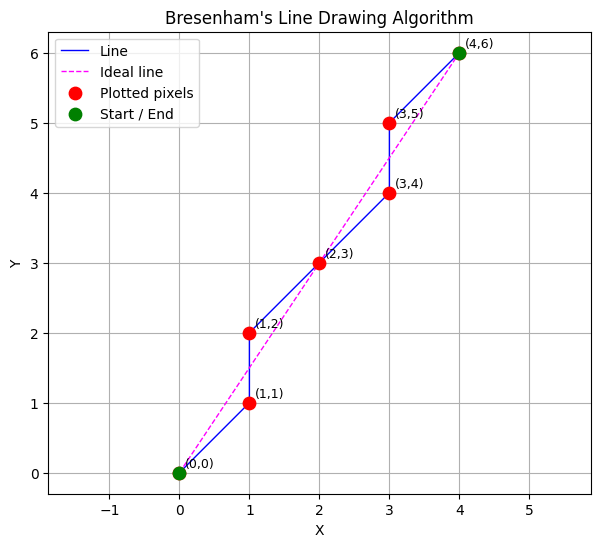

In [5]:
import matplotlib.pyplot as plt
def bresenham_line(x1, y1, x2, y2):
    print("\n ---Bresenham's Line Drawing Algorithm--- ")
    print("Starting point: ",x1,y1)
    print("Ending point: ",x2,y2)
    m = (y2 - y1)/(x2 - x1)
    print("Slope:",m)
    dx = abs(x2 - x1)
    dy = abs(y2 - y1)

    sx = 1 if x2 > x1 else -1   # step direction for x
    sy = 1 if y2 > y1 else -1   # step direction for y

    x, y = x1, y1
    points = []
    # Conditions
    if dx > dy:
        print("Slope < 1: decision based on x")
        p = 2 * dy - dx
        for _ in range(dx + 1):
            points.append((x, y))
            if p >= 0:
                y += sy
                p -= 2 * dx
            x += sx
            p += 2 * dy
    else:
        print("Slope < 1: decision based on y")
        p = 2 * dx - dy
        for _ in range(dy + 1):
            points.append((x, y))
            if p >= 0:
                x += sx
                p -= 2 * dy
            y += sy
            p += 2 * dx
    return points

def plot_bresenham(points,x1, y1, x2, y2):
    xs = [p[0] for p in points]
    ys = [p[1] for p in points]

    plt.figure(figsize=(7, 6))
    plt.plot(xs, ys, color="blue", linewidth=1, label="Line")
    # Plot the ideal mathematical line for comparison
    plt.plot([x1, x2], [y1, y2], color="magenta", linestyle="--", linewidth=1, label="Ideal line")

    plt.scatter(xs, ys, color="red", s=80, zorder=6, label="Plotted pixels")
    # Highlight the original start/end pixels
    plt.scatter([x1, x2], [y1, y2], color="green", s=80,
                marker="o", zorder=6, label="Start / End")

    for x,y in points: # Text annotation (Coordinates)
     plt.text(x + 0.08, y + 0.08, f"({x},{y})", fontsize=9)
    plt.title("Bresenham's Line Drawing Algorithm")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(True)
    plt.legend()
    plt.axis('equal')
    plt.show()


if __name__ == "__main__":
  #Enter Coordinates
  x1 = int(input("Enter x1: "))
  y1 = int(input("Enter y1: "))
  x2 = int(input("Enter x2: "))
  y2 = int(input("Enter y2: "))
  result = bresenham_line(x1, y1, x2, y2)
  print("\nPoints on the line:")
  print(result)

  plot_bresenham(result,x1, y1, x2, y2)



3. DDA Scan Conversion

In [6]:
import matplotlib.pyplot as plt

In [7]:
def direct_line(x1,y1,x2,y2):
  pixels = []
  print("\n ---Direct Line Equation Method--- ")
  print("Starting point: ",x1,y1)
  print("Ending point: ",x2,y2)
  dx = x2 - x1
  dy = y2 - y1

  #For only vertical line
  if dx==0:
    print("Case: Vertical Line.\n")
    print("Slope is undefined.\n")
    start_y = min(y1,y2)
    end_y = max(y1,y2)
    for y in range(start_y, end_y+1):
      pixels.append((x1,y))
      print(f"x={x1}, y={y}, pixels -> {(x1,y)}")

  else:
        m = dy/dx
        b = y1 - m*x1
        print("Slope:",m)
        print("Y-intercept:",b)

        if abs(m) <= 1:
          print("Case: Shallow Line.\n")
          start_x = min(x1,x2)
          end_x = max(x1,x2)
          for x in range(start_x, end_x+1):
            y = m*x+b
            round_y = round(y)
            pixels.append((x,round_y))
            print(f"x={x}, y={round_y}, pixels -> {(x,round_y)}")
        else:
          print("Case: Steep Line.\n")
          start_y = min(y1,y2)
          end_y = max(y1,y2)
          for y in range(start_y, end_y+1):
            x = (y-b)/m
            round_x = round(x)
            pixels.append((round_x,y))
            print(f"x={round_x}, y={y}, pixels -> {(round_x,y)}")
  return pixels

In [8]:
########## MAIN PROGRAM ##########

#Enter Coordinates

x1 = int(input("Enter x1: "))
y1 = int(input("Enter y1: "))
x2 = int(input("Enter x2: "))
y2 = int(input("Enter y2: "))

#Calling Function

pixels = direct_line(x1,y1,x2,y2)

#Display Functions

print(pixels)

Enter x1: 0
Enter y1: 0
Enter x2: 6
Enter y2: 18

 ---Direct Line Equation Method--- 
Starting point:  0 0
Ending point:  6 18
Slope: 3.0
Y-intercept: 0.0
Case: Steep Line.

x=0, y=0, pixels -> (0, 0)
x=0, y=1, pixels -> (0, 1)
x=1, y=2, pixels -> (1, 2)
x=1, y=3, pixels -> (1, 3)
x=1, y=4, pixels -> (1, 4)
x=2, y=5, pixels -> (2, 5)
x=2, y=6, pixels -> (2, 6)
x=2, y=7, pixels -> (2, 7)
x=3, y=8, pixels -> (3, 8)
x=3, y=9, pixels -> (3, 9)
x=3, y=10, pixels -> (3, 10)
x=4, y=11, pixels -> (4, 11)
x=4, y=12, pixels -> (4, 12)
x=4, y=13, pixels -> (4, 13)
x=5, y=14, pixels -> (5, 14)
x=5, y=15, pixels -> (5, 15)
x=5, y=16, pixels -> (5, 16)
x=6, y=17, pixels -> (6, 17)
x=6, y=18, pixels -> (6, 18)
[(0, 0), (0, 1), (1, 2), (1, 3), (1, 4), (2, 5), (2, 6), (2, 7), (3, 8), (3, 9), (3, 10), (4, 11), (4, 12), (4, 13), (5, 14), (5, 15), (5, 16), (6, 17), (6, 18)]


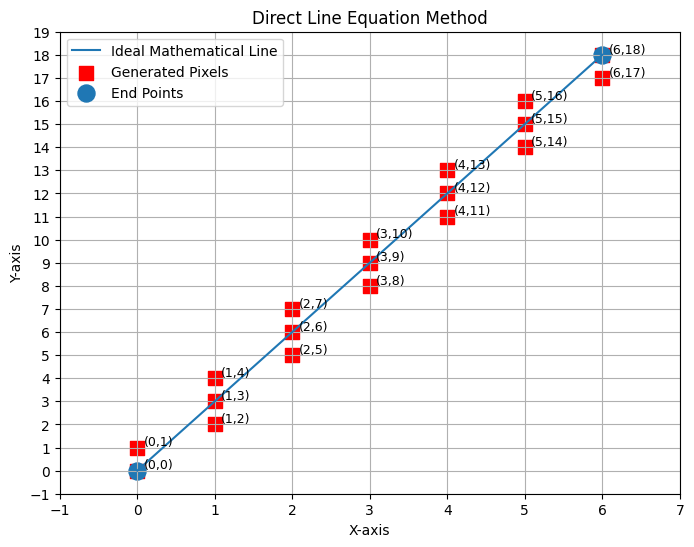

In [9]:
## Plotting pixels ##

x_pixels = [p[0] for p in pixels]
y_pixels = [p[1] for p in pixels]

plt.figure(figsize=(8,6)) # Fixed figsize syntax

plt.plot(
    [x1,x2],
    [y1,y2],
    label = "Ideal Mathematical Line"
)

plt.scatter(
    x_pixels,
    y_pixels,
    s = 100,
    marker="s",
    color="red",
    label= "Generated Pixels"
)

plt.scatter(
    [x1,x2],
    [y1,y2],
    s = 150,
    marker="o",
    label= "End Points"
)

for x,y in pixels:
  plt.text(x + 0.08, y + 0.08, f"({x},{y})", fontsize=9) # Corrected text annotation


plt.xticks(range(min(x1,x2)-1,max(x1,x2)+2)) # Fixed plt.xsticks to plt.xticks
plt.yticks(range(min(y1,y2)-1,max(y1,y2)+2))



plt.xlim(min(x1,x2)-1,max(x1,x2)+1) # Fixed plt.xlim to plt.xlim
plt.ylim(min(y1,y2)-1,max(y1,y2)+1)
plt.grid(True)
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("Direct Line Equation Method")
plt.legend()
plt.show()